## Feature Evaluation

Creator: Mohammad Vali Sanian (mohammad.sanian@helsinki.fi) (mv10@sanger.ac.uk).

Date of Creation: 17.06.2024

Date of Last Modification: 17.06.2024

## Import

In [60]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder
import pandas as pd
from tqdm import tqdm
import numpy as np
import scib_metrics
import scanpy as sc


## Extracting Embeddings Simulated data easy version

In [75]:
#Change eval.yaml accordingly if you wants to get average from different part of the  output 
#Change   top_niche, top_cell_type
!python eval.py --fname configs/eval.yaml --devices cuda:0

INFO:root:called-params configs/eval.yaml
INFO:root:loaded params...
{   'data': {   'Total_seed': 10,
                'batch_size': 500,
                'data_path': '/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/simulated.dataset',
                'num_workers': 12,
                'pin_mem': True,
                'seq_len': 512,
                'split': 0.2,
                'vocab_size': 1356},
    'logging': {   'folder': 'logs/sim_ema0.8_100_200_40_1_1_seed',
                   'save_folder': 'out_put/sim_data_top256/cell_neighborhood_token',
                   'write_tag': 'jepa'},
    'mask': {   'context_mask_size': 200,
                'n_contexts': 1,
                'n_targets': 1,
                'target_mask_size': 100,
                'top_cell_type': 256,
                'top_niche': 512},
    'meta': {   'copy_data': False,
                'enc_depth': 1,
                'enc_emb_dim': 192,
                'load_checkpoint': True,
                'model_name': 

## Extracting Embeddings Simulated data hard version

In [55]:
#Change eval.yaml accordingly if you wants to get average from different part of the  output 
#Change   top_niche, top_cell_type
!python eval.py --fname configs/eval.yaml --devices cuda:0

INFO:root:called-params configs/eval.yaml
INFO:root:loaded params...
{   'data': {   'batch_size': 500,
                'data_path': '/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/simulated_hard.dataset',
                'num_workers': 12,
                'pin_mem': True,
                'seq_len': 512,
                'split': 0.2,
                'vocab_size': 1356},
    'logging': {   'folder': 'logs/sim_hard_ema0.8_100_200_40_1_1_seed',
                   'save_folder': 'out_put/sim_data_hard/cell_neighborhood_token',
                   'write_tag': 'jepa'},
    'mask': {   'context_mask_size': 200,
                'n_contexts': 1,
                'n_targets': 1,
                'target_mask_size': 100,
                'top_cell_type': 10,
                'top_niche': 266},
    'meta': {   'copy_data': False,
                'enc_depth': 1,
                'enc_emb_dim': 192,
                'load_checkpoint': True,
                'model_name': 'gt_base',
                

## Extracting Embeddings for nanostring

In [9]:
#Change eval.yaml accordingly if you wants to get average from different part of the  output 
#Change   top_niche, top_cell_type
!python eval.py --fname configs/eval.yaml --devices cuda:0

INFO:root:called-params configs/eval.yaml
INFO:root:loaded params...
{   'data': {   'Total_seed': 10,
                'batch_size': 500,
                'data_path': '/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/cell_neighborhood_tokenizer.dataset',
                'num_workers': 12,
                'pin_mem': True,
                'seq_len': 512,
                'split': 0.2,
                'vocab_size': 6033},
    'logging': {   'folder': 'logs/nanostring_ema0.8_100_200_40_1_1_seed',
                   'save_folder': 'out_put/nanostringtop256/cell_neighborhood_token',
                   'write_tag': 'jepa'},
    'mask': {   'context_mask_size': 200,
                'n_contexts': 1,
                'n_targets': 1,
                'target_mask_size': 100,
                'top_cell_type': 256,
                'top_niche': 512},
    'meta': {   'copy_data': False,
                'enc_depth': 1,
                'enc_emb_dim': 192,
                'load_checkpoint': True,
    

## Logistic reg with different seed

In [5]:
import os
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score
from tqdm import tqdm

def prepare_dataframes(df, feature_prefix='feature_', label_column='cluster_label', num_features=192):
    # Extract features and labels
    feature_columns = [f'{feature_prefix}{i}' for i in range(num_features)]
    X = df[feature_columns].values

    # Convert label_column to integers, handling NaN values
    le = LabelEncoder()
    y = df[label_column]
    y = y.dropna()  # Drop NaN values for label
    X = df.loc[y.index, feature_columns].values  # Keep only rows with non-NaN labels
    y = le.fit_transform(y)
    
    return X, y

def create_dataloaders(X, y, batch_size=32):
    # Create DataLoader
    dataset = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long))
    data_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    return data_loader

def train_model(model, train_loader):
    X_train, y_train = [], []
    for X_batch, y_batch in tqdm(train_loader):
        X_train.extend(X_batch.numpy())
        y_train.extend(y_batch.numpy())
    model.fit(X_train, y_train)

def evaluate_model(model, data_loader):
    X, y = [], []
    for X_batch, y_batch in data_loader:
        X.extend(X_batch.numpy())
        y.extend(y_batch.numpy())
    preds = model.predict(X)
    f1_weighted = f1_score(y, preds, average='weighted')
    return f1_weighted

def run_logistic_regression(train_df, test_df, label_column):
    # Prepare data
    X_train, y_train = prepare_dataframes(train_df, label_column=label_column)
    X_test, y_test = prepare_dataframes(test_df, label_column=label_column)

    # Create DataLoaders
    train_loader = create_dataloaders(X_train, y_train)
    test_loader = create_dataloaders(X_test, y_test)

    # Define the logistic regression model
    model = LogisticRegression(max_iter=200, solver='lbfgs', multi_class='multinomial')

    # Train the model
    train_model(model, train_loader)

    # Evaluate the model
    train_f1_weighted = evaluate_model(model, train_loader)
    test_f1_weighted = evaluate_model(model, test_loader)

    return train_f1_weighted, test_f1_weighted

def main(folder_path,total_seed):
    seeds = range(total_seed)
    niche_label_train_results = []
    niche_label_test_results = []
    cell_type_train_results = []
    cell_type_test_results = []

    for seed in seeds:
        train_file = os.path.join(folder_path, f'aggregated_features_seed_{seed}.csv')
        test_file = os.path.join(folder_path, f'aggregated_features_seed_{seed}.csv')

        train_df = pd.read_csv(train_file)
        test_df = pd.read_csv(test_file)

        # Filter train and test dataframes for "train" and "test" respectively
        train_df = train_df[train_df['split'] == 'train']
        test_df = test_df[test_df['split'] == 'test']

        # Run logistic regression for niche_label
        train_f1_weighted_niche, test_f1_weighted_niche = run_logistic_regression(train_df, test_df, 'niche_label')
        niche_label_train_results.append(train_f1_weighted_niche)
        niche_label_test_results.append(test_f1_weighted_niche)

        # Run logistic regression for cell_type
        train_f1_weighted_cell, test_f1_weighted_cell = run_logistic_regression(train_df, test_df, 'cell_type')
        cell_type_train_results.append(train_f1_weighted_cell)
        cell_type_test_results.append(test_f1_weighted_cell)

        print(f"Seed {seed} - Niche Label Train Weighted F1 Score: {train_f1_weighted_niche}")
        print(f"Seed {seed} - Niche Label Test Weighted F1 Score: {test_f1_weighted_niche}")
        print(f"Seed {seed} - Cell Type Train Weighted F1 Score: {train_f1_weighted_cell}")
        print(f"Seed {seed} - Cell Type Test Weighted F1 Score: {test_f1_weighted_cell}")

    avg_niche_label_train_f1 = sum(niche_label_train_results) / len(niche_label_train_results)
    avg_niche_label_test_f1 = sum(niche_label_test_results) / len(niche_label_test_results)
    avg_cell_type_train_f1 = sum(cell_type_train_results) / len(cell_type_train_results)
    avg_cell_type_test_f1 = sum(cell_type_test_results) / len(cell_type_test_results)

    print("\nAverage Niche Label Train Weighted F1 Score:", avg_niche_label_train_f1)
    print("Average Niche Label Test Weighted F1 Score:", avg_niche_label_test_f1)
    print("Average Cell Type Train Weighted F1 Score:", avg_cell_type_train_f1)
    print("Average Cell Type Test Weighted F1 Score:", avg_cell_type_test_f1)


## Benchmark Simulated data easy version top 10

In [57]:
folder_path = '/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/out_put/sim_data/cell_neighborhood_token'  # Update this with the path to your folder containing the CSV files
main(folder_path,10)

100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 5907.27it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 0 - Niche Label Train Weighted F1 Score: 0.8608788749508401
Seed 0 - Niche Label Test Weighted F1 Score: 0.8395218563463086
Seed 0 - Cell Type Train Weighted F1 Score: 1.0
Seed 0 - Cell Type Test Weighted F1 Score: 0.9994987908460369


100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 6158.28it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 1 - Niche Label Train Weighted F1 Score: 0.8585969792741057
Seed 1 - Niche Label Test Weighted F1 Score: 0.852966174505261
Seed 1 - Cell Type Train Weighted F1 Score: 1.0
Seed 1 - Cell Type Test Weighted F1 Score: 1.0


100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 6146.04it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 2 - Niche Label Train Weighted F1 Score: 0.8570963011817965
Seed 2 - Niche Label Test Weighted F1 Score: 0.8603449601427106
Seed 2 - Cell Type Train Weighted F1 Score: 1.0
Seed 2 - Cell Type Test Weighted F1 Score: 1.0


... (10 outputs left out)

100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 6140.71it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 8 - Niche Label Train Weighted F1 Score: 0.8612155880618513
Seed 8 - Niche Label Test Weighted F1 Score: 0.8488204862265211
Seed 8 - Cell Type Train Weighted F1 Score: 1.0
Seed 8 - Cell Type Test Weighted F1 Score: 0.9994987240598969


100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 6255.75it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 9 - Niche Label Train Weighted F1 Score: 0.860964443518961
Seed 9 - Niche Label Test Weighted F1 Score: 0.8397164114162436
Seed 9 - Cell Type Train Weighted F1 Score: 1.0
Seed 9 - Cell Type Test Weighted F1 Score: 1.0

Average Niche Label Train Weighted F1 Score: 0.8603935355668189
Average Niche Label Test Weighted F1 Score: 0.8481373095402087
Average Cell Type Train Weighted F1 Score: 1.0
Average Cell Type Test Weighted F1 Score: 0.9997493704578069


## Benchmark Simulated data easy version top 30

In [74]:
folder_path = '/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/out_put/sim_data_top30/cell_neighborhood_token'  # Update this with the path to your folder containing the CSV files
main(folder_path,10)

100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 5435.20it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 0 - Niche Label Train Weighted F1 Score: 0.8876847091911848
Seed 0 - Niche Label Test Weighted F1 Score: 0.8692643206981746
Seed 0 - Cell Type Train Weighted F1 Score: 1.0
Seed 0 - Cell Type Test Weighted F1 Score: 1.0


100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 5813.15it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 1 - Niche Label Train Weighted F1 Score: 0.8876098343580171
Seed 1 - Niche Label Test Weighted F1 Score: 0.8720553441984771
Seed 1 - Cell Type Train Weighted F1 Score: 1.0
Seed 1 - Cell Type Test Weighted F1 Score: 1.0


100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 5708.62it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 2 - Niche Label Train Weighted F1 Score: 0.885710077576178
Seed 2 - Niche Label Test Weighted F1 Score: 0.8841986559669321
Seed 2 - Cell Type Train Weighted F1 Score: 1.0
Seed 2 - Cell Type Test Weighted F1 Score: 1.0


... (10 outputs left out)

100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 5838.40it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 8 - Niche Label Train Weighted F1 Score: 0.8875928961093775
Seed 8 - Niche Label Test Weighted F1 Score: 0.8726661362345879
Seed 8 - Cell Type Train Weighted F1 Score: 1.0
Seed 8 - Cell Type Test Weighted F1 Score: 1.0


100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 5836.09it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 9 - Niche Label Train Weighted F1 Score: 0.8827891031014024
Seed 9 - Niche Label Test Weighted F1 Score: 0.8822472736987476
Seed 9 - Cell Type Train Weighted F1 Score: 1.0
Seed 9 - Cell Type Test Weighted F1 Score: 1.0

Average Niche Label Train Weighted F1 Score: 0.8852383142033657
Average Niche Label Test Weighted F1 Score: 0.8776836584632154
Average Cell Type Train Weighted F1 Score: 1.0
Average Cell Type Test Weighted F1 Score: 1.0


## Benchmark Simulated data easy  version top 256

In [76]:
folder_path = '/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/out_put/sim_data_top256/cell_neighborhood_token'  # Update this with the path to your folder containing the CSV files
main(folder_path,10)

100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 5521.29it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 3492.23it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Seed 0 - Niche Label Train Weighted F1 Score: 0.842145606047571
Seed 0 - Niche Label Test Weighted F1 Score: 0.8347633903628666
Seed 0 - Cell Type Train Weighted F1 Score: 0.9994986375990111
Seed 0 - Cell Type Test Weighted F1 Score: 0.9984888464956969


100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 5798.23it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 3646.28it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Seed 1 - Niche Label Train Weighted F1 Score: 0.842564585232674
Seed 1 - Niche Label Test Weighted F1 Score: 0.8288883983575797
Seed 1 - Cell Type Train Weighted F1 Score: 0.998868173192526
Seed 1 - Cell Type Test Weighted F1 Score: 0.998994187444936


100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 5643.33it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 3647.46it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Seed 2 - Niche Label Train Weighted F1 Score: 0.8396925939095929
Seed 2 - Niche Label Test Weighted F1 Score: 0.8461851691958788
Seed 2 - Cell Type Train Weighted F1 Score: 0.9987420418008989
Seed 2 - Cell Type Test Weighted F1 Score: 0.9969705040626055


... (10 outputs left out)

100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 5741.00it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 3620.82it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Seed 8 - Niche Label Train Weighted F1 Score: 0.8414590492964489
Seed 8 - Niche Label Test Weighted F1 Score: 0.8321605007939468
Seed 8 - Cell Type Train Weighted F1 Score: 0.9993729099896561
Seed 8 - Cell Type Test Weighted F1 Score: 1.0


100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 5851.20it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 3671.19it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Seed 9 - Niche Label Train Weighted F1 Score: 0.8450546619543863
Seed 9 - Niche Label Test Weighted F1 Score: 0.8232961580538956
Seed 9 - Cell Type Train Weighted F1 Score: 0.9992470104516334
Seed 9 - Cell Type Test Weighted F1 Score: 0.9989949548192771

Average Niche Label Train Weighted F1 Score: 0.8421558208253404
Average Niche Label Test Weighted F1 Score: 0.835609615361078
Average Cell Type Train Weighted F1 Score: 0.9992338940322145
Average Cell Type Test Weighted F1 Score: 0.9989933638326891


## Benchmark Simulated data hard version top 10

In [58]:
folder_path = '/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/out_put/sim_data_hard/cell_neighborhood_token'  # Update this with the path to your folder containing the CSV files
main(folder_path,10)

100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 6197.22it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 0 - Niche Label Train Weighted F1 Score: 0.6503827828410212
Seed 0 - Niche Label Test Weighted F1 Score: 0.5803396221714141
Seed 0 - Cell Type Train Weighted F1 Score: 0.6156230722536036
Seed 0 - Cell Type Test Weighted F1 Score: 0.5569285246657929


100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 6292.27it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 1 - Niche Label Train Weighted F1 Score: 0.6440615222290427
Seed 1 - Niche Label Test Weighted F1 Score: 0.5951709340696107
Seed 1 - Cell Type Train Weighted F1 Score: 0.6131146687855564
Seed 1 - Cell Type Test Weighted F1 Score: 0.5803574936268787


100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 6200.01it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 2 - Niche Label Train Weighted F1 Score: 0.650519587909276
Seed 2 - Niche Label Test Weighted F1 Score: 0.5806785234127119
Seed 2 - Cell Type Train Weighted F1 Score: 0.6161148024861832
Seed 2 - Cell Type Test Weighted F1 Score: 0.5714712988352663


... (11 outputs left out)

Seed 8 - Niche Label Train Weighted F1 Score: 0.6447589477521214
Seed 8 - Niche Label Test Weighted F1 Score: 0.5767903038228203
Seed 8 - Cell Type Train Weighted F1 Score: 0.6160555815971231
Seed 8 - Cell Type Test Weighted F1 Score: 0.5643335345438811


100%|█████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:00<00:00, 6259.15it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 9 - Niche Label Train Weighted F1 Score: 0.6393313261201052
Seed 9 - Niche Label Test Weighted F1 Score: 0.5960113162325298
Seed 9 - Cell Type Train Weighted F1 Score: 0.6170789395531026
Seed 9 - Cell Type Test Weighted F1 Score: 0.5597984050090243

Average Niche Label Train Weighted F1 Score: 0.6479753724045635
Average Niche Label Test Weighted F1 Score: 0.5829055567192973
Average Cell Type Train Weighted F1 Score: 0.6161652619908746
Average Cell Type Test Weighted F1 Score: 0.5640345776618648


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Benchmark nanostring

In [8]:
# Benchmark when average top 10 
folder_path = '/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/out_put/nanostringtop10/cell_neighborhood_token'  # Update this with the path to your folder containing the CSV files
main(folder_path,10)

100%|███████████████████████████████████████████████████████████████████████████████████| 4704/4704 [00:00<00:00, 5389.42it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 0 - Niche Label Train Weighted F1 Score: 0.5162443933144332
Seed 0 - Niche Label Test Weighted F1 Score: 0.5136030060408562
Seed 0 - Cell Type Train Weighted F1 Score: 0.8107989710689593
Seed 0 - Cell Type Test Weighted F1 Score: 0.810362825308719


100%|███████████████████████████████████████████████████████████████████████████████████| 4704/4704 [00:00<00:00, 5371.79it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 1 - Niche Label Train Weighted F1 Score: 0.5067769382487152
Seed 1 - Niche Label Test Weighted F1 Score: 0.5103277951561853
Seed 1 - Cell Type Train Weighted F1 Score: 0.8022501456800493
Seed 1 - Cell Type Test Weighted F1 Score: 0.8046459257058273


100%|███████████████████████████████████████████████████████████████████████████████████| 4704/4704 [00:00<00:00, 5383.08it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 2 - Niche Label Train Weighted F1 Score: 0.5039014055763852
Seed 2 - Niche Label Test Weighted F1 Score: 0.496740303049721
Seed 2 - Cell Type Train Weighted F1 Score: 0.817864313863986
Seed 2 - Cell Type Test Weighted F1 Score: 0.8169833247789552


... (10 outputs left out)

100%|███████████████████████████████████████████████████████████████████████████████████| 4704/4704 [00:00<00:00, 5252.45it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 8 - Niche Label Train Weighted F1 Score: 0.5188696444164363
Seed 8 - Niche Label Test Weighted F1 Score: 0.5199946158474358
Seed 8 - Cell Type Train Weighted F1 Score: 0.8181660627949121
Seed 8 - Cell Type Test Weighted F1 Score: 0.8139931335663377


100%|███████████████████████████████████████████████████████████████████████████████████| 4704/4704 [00:00<00:00, 5455.15it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 9 - Niche Label Train Weighted F1 Score: 0.49651191888003915
Seed 9 - Niche Label Test Weighted F1 Score: 0.4985207623897329
Seed 9 - Cell Type Train Weighted F1 Score: 0.8112361135051946
Seed 9 - Cell Type Test Weighted F1 Score: 0.8106724856043824

Average Niche Label Train Weighted F1 Score: 0.5048307812874463
Average Niche Label Test Weighted F1 Score: 0.5042842941010174
Average Cell Type Train Weighted F1 Score: 0.8073621339051155
Average Cell Type Test Weighted F1 Score: 0.806745853871781


In [11]:
# Benchmark when average top 256
folder_path = '/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/out_put/nanostringtop256/cell_neighborhood_token'  # Update this with the path to your folder containing the CSV files
main(folder_path,10)

100%|███████████████████████████████████████████████████████████████████████████████████| 4704/4704 [00:00<00:00, 5405.29it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 0 - Niche Label Train Weighted F1 Score: 0.48485804206874844
Seed 0 - Niche Label Test Weighted F1 Score: 0.477771321737405
Seed 0 - Cell Type Train Weighted F1 Score: 0.7954544033884828
Seed 0 - Cell Type Test Weighted F1 Score: 0.7938886016394481


100%|███████████████████████████████████████████████████████████████████████████████████| 4704/4704 [00:00<00:00, 5316.26it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 1 - Niche Label Train Weighted F1 Score: 0.46507845971262557
Seed 1 - Niche Label Test Weighted F1 Score: 0.47165324125423175
Seed 1 - Cell Type Train Weighted F1 Score: 0.7873293319161961
Seed 1 - Cell Type Test Weighted F1 Score: 0.7879335548152689


100%|███████████████████████████████████████████████████████████████████████████████████| 4704/4704 [00:00<00:00, 5332.21it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 2 - Niche Label Train Weighted F1 Score: 0.45514274117889436
Seed 2 - Niche Label Test Weighted F1 Score: 0.4523020520880963
Seed 2 - Cell Type Train Weighted F1 Score: 0.7923602771229336
Seed 2 - Cell Type Test Weighted F1 Score: 0.7911593757187867


... (10 outputs left out)

100%|███████████████████████████████████████████████████████████████████████████████████| 4704/4704 [00:00<00:00, 5406.44it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 8 - Niche Label Train Weighted F1 Score: 0.5013729133899071
Seed 8 - Niche Label Test Weighted F1 Score: 0.5011724387361226
Seed 8 - Cell Type Train Weighted F1 Score: 0.8135706116226656
Seed 8 - Cell Type Test Weighted F1 Score: 0.8096182227303125


100%|███████████████████████████████████████████████████████████████████████████████████| 4704/4704 [00:00<00:00, 5416.60it/s]
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
100%|██████████████████████████████████████████████

Seed 9 - Niche Label Train Weighted F1 Score: 0.4674948555483919
Seed 9 - Niche Label Test Weighted F1 Score: 0.4668297309035613
Seed 9 - Cell Type Train Weighted F1 Score: 0.7998085881226588
Seed 9 - Cell Type Test Weighted F1 Score: 0.8037586124846563

Average Niche Label Train Weighted F1 Score: 0.47141331125293007
Average Niche Label Test Weighted F1 Score: 0.47001311489868636
Average Cell Type Train Weighted F1 Score: 0.792122038541406
Average Cell Type Test Weighted F1 Score: 0.7915202537305427


## Umap

In [16]:
import umap
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def prepare_features_labels(df, label_column='cluster_label'):
    """
    Extracts features and labels from the DataFrame.

    Args:
    df (pd.DataFrame): DataFrame containing features and labels.
    label_column (str): Name of the column containing labels.

    Returns:
    features (np.ndarray): Array of feature values.
    labels (np.ndarray): Array of labels.
    """
    features = df.drop(columns=[label_column]).values
    labels = df[label_column].values
    return features, labels

def apply_umap(features, n_neighbors=15, min_dist=0.1, n_components=2, random_state=42):
    """
    Applies UMAP to the features.

    Args:
    features (np.ndarray): Array of feature values.
    n_neighbors (int): Number of neighbors to consider.
    min_dist (float): Minimum distance between points in the low-dimensional space.
    n_components (int): Number of dimensions in the UMAP embedding.
    random_state (int): Random state for reproducibility.

    Returns:
    umap_embedding (np.ndarray): UMAP embedding of the features.
    """
    umap_model = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=n_components, random_state=random_state)
    umap_embedding = umap_model.fit_transform(features)
    return umap_embedding

def plot_umap(umap_embedding, labels, title='UMAP projection of the dataset', palette='hsv'):
    """
    Plots the UMAP embedding with labels.

    Args:
    umap_embedding (np.ndarray): UMAP embedding of the features.
    labels (np.ndarray): Array of labels.
    title (str): Title of the plot.
    palette (str): Color palette for the plot.

    Returns:
    None
    """
    umap_df = pd.DataFrame(umap_embedding, columns=['UMAP1', 'UMAP2'])
    umap_df['cluster_label'] = labels

    plt.figure(figsize=(10, 8))
    scatter_plot = sns.scatterplot(
        x='UMAP1', y='UMAP2',
        hue='cluster_label',
        palette=sns.color_palette(palette, len(set(labels))),
        data=umap_df,
        legend="full",
        alpha=0.6
    )
    plt.title(title)

    # Move the legend outside the plot
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
    plt.show()

def run_umap_visualization(df, label_column='cluster_label', n_neighbors=15, min_dist=0.1, n_components=2, random_state=42, plot_title='UMAP projection of the dataset', palette='hsv'):
    """
    Runs the full UMAP visualization pipeline.

    Args:
    df (pd.DataFrame): DataFrame containing features and labels.
    label_column (str): Name of the column containing labels.
    n_neighbors (int): Number of neighbors to consider.
    min_dist (float): Minimum distance between points in the low-dimensional space.
    n_components (int): Number of dimensions in the UMAP embedding.
    random_state (int): Random state for reproducibility.
    plot_title (str): Title of the plot.
    palette (str): Color palette for the plot.

    Returns:
    None
    """
    features, labels = prepare_features_labels(df, label_column)
    umap_embedding = apply_umap(features, n_neighbors, min_dist, n_components, random_state)
    plot_umap(umap_embedding, labels, plot_title, palette)

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


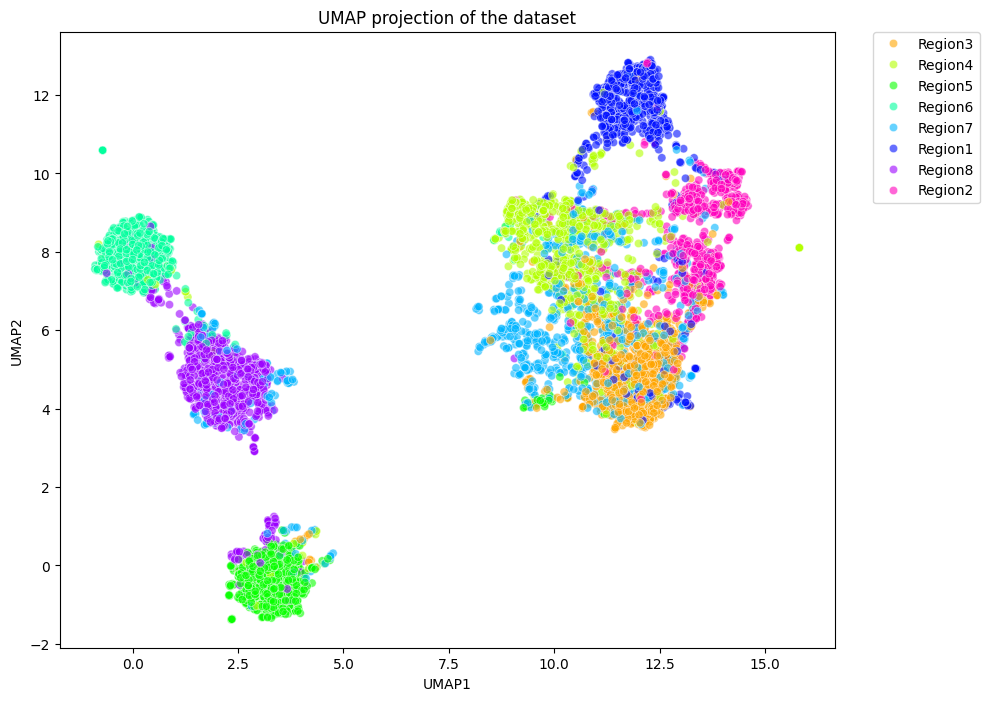

In [43]:
train_data = pd.read_csv('/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/new_data_train_niche_type_sim_.8_100_200_1target_top30.csv')
run_umap_visualization(train_data)

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


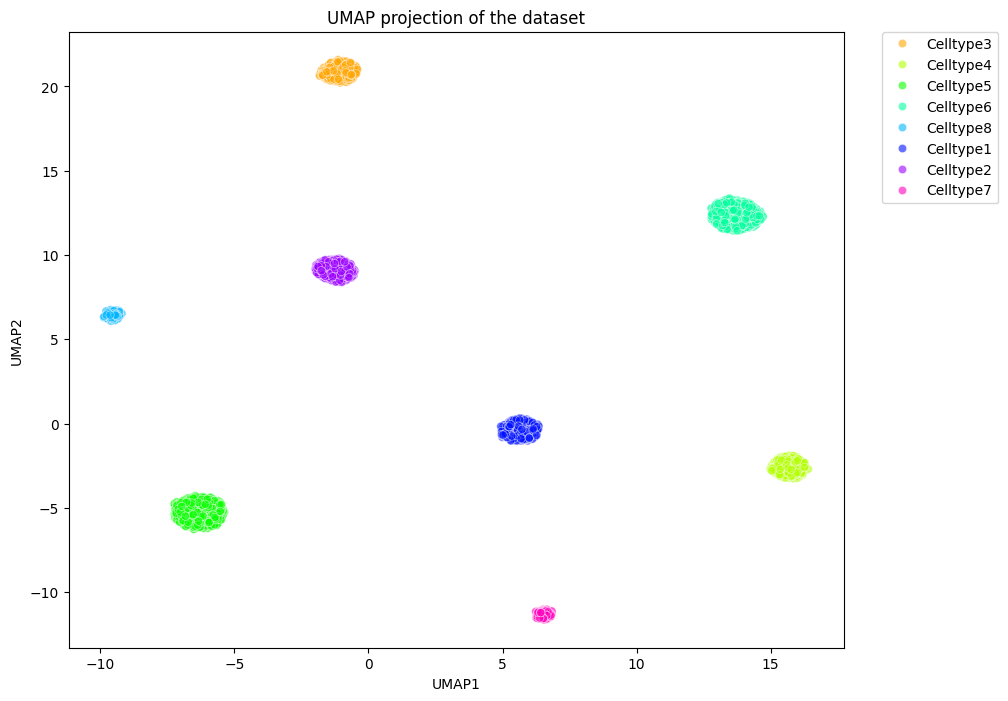

In [38]:
train_data = pd.read_csv('/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/new_data_train_cell_type_sim_.8_100_200_1target_top30.csv')
run_umap_visualization(train_data)

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


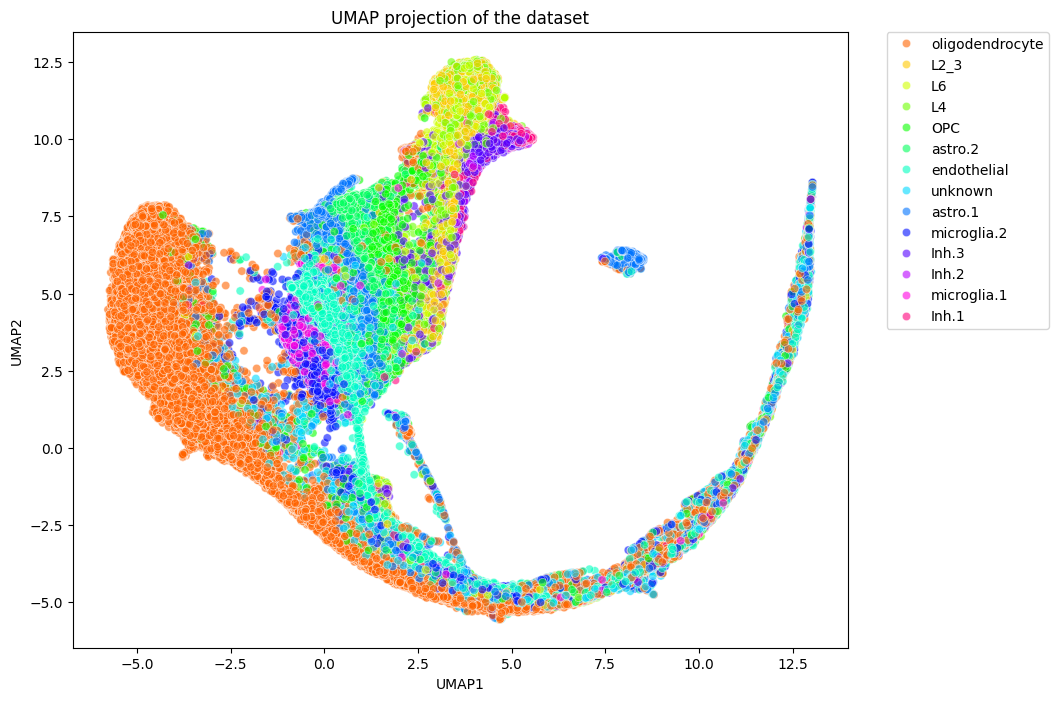

In [20]:
train_data = pd.read_csv('/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/new_data_train_cell_type_0.8_30_200_1target.csv')
run_umap_visualization(train_data)

In [ ]:
train_data = pd.read_csv('/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/new_data_train_cell_type_0.8_100_200_1target_top20.csv')
run_umap_visualization(train_data)

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


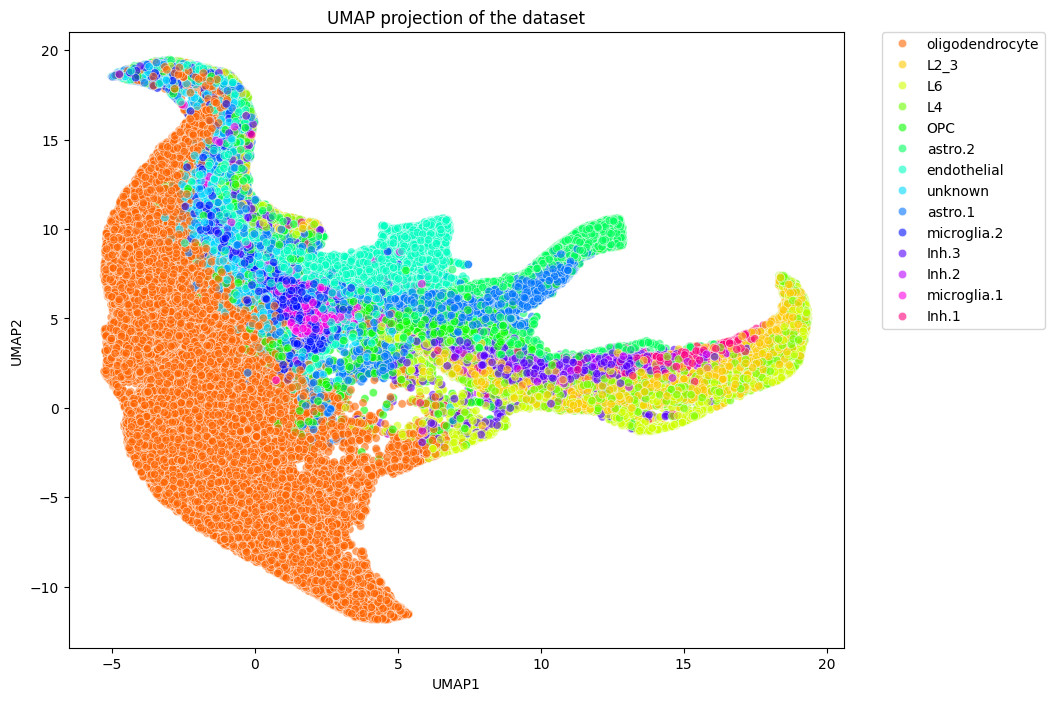

In [17]:
train_data = pd.read_csv('/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/new_data_train_cell_type_0.1_30_200.csv')
run_umap_visualization(train_data)

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


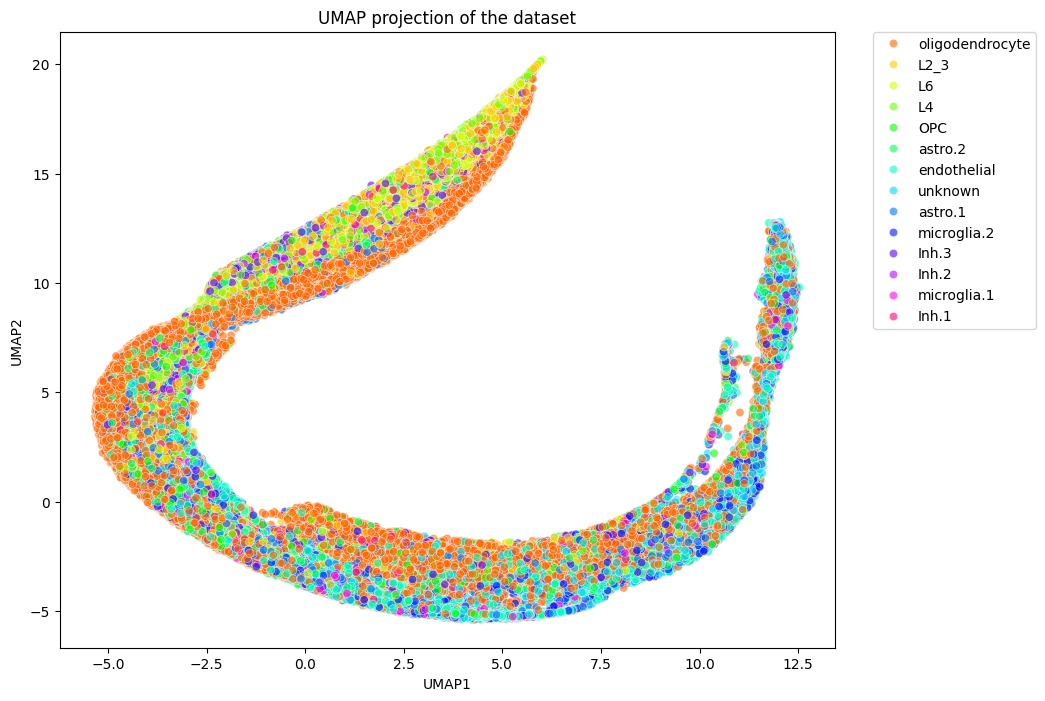

In [11]:
train_data = pd.read_csv('/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/new_data_train_cell_type_0.4_epoch2.csv')
run_umap_visualization(train_data)

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


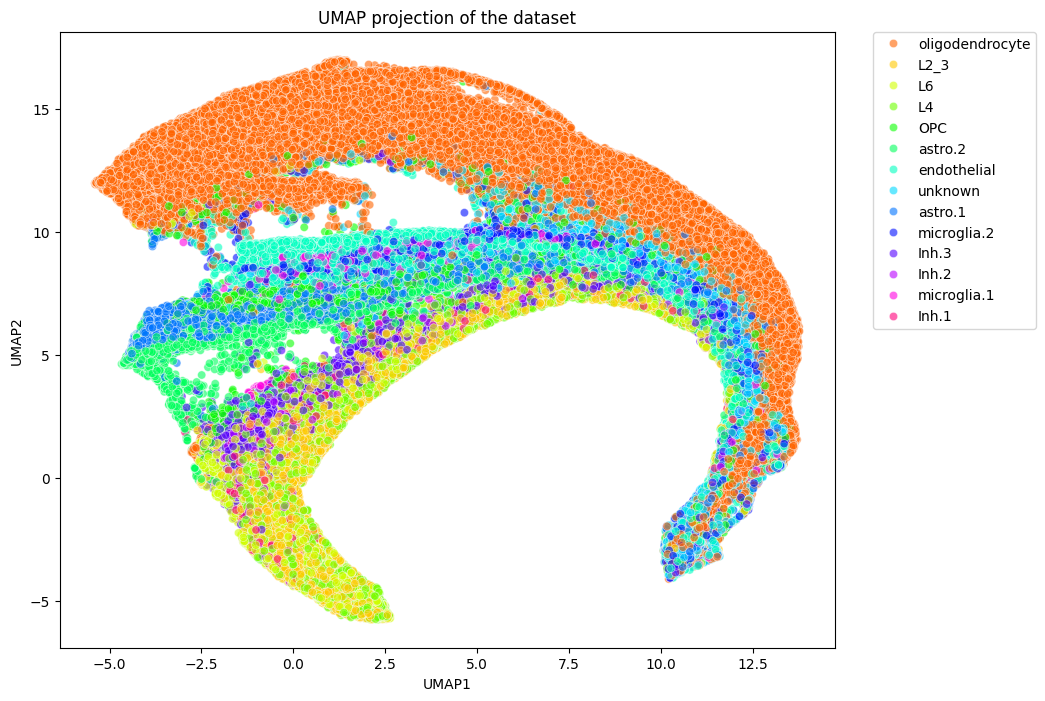

In [3]:
train_data = pd.read_csv('/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/new_data_train_cell_type_0.996.csv')
run_umap_visualization(train_data)

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


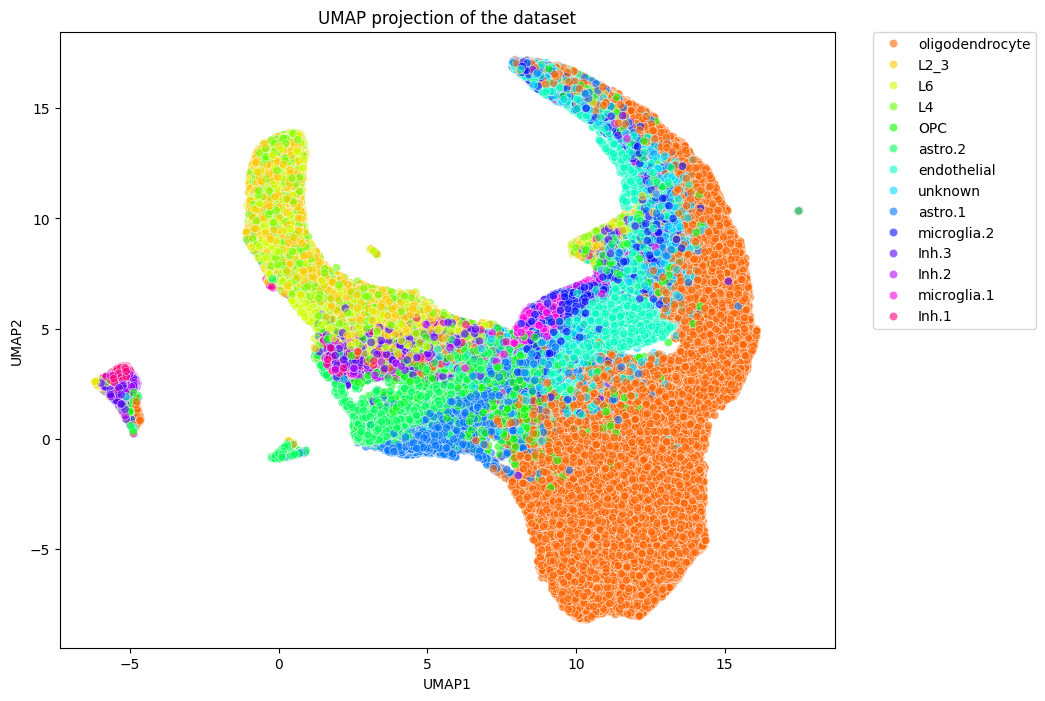

In [6]:
train_data = pd.read_csv('/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/new_data_train_cell_type.csv')
run_umap_visualization(train_data)

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


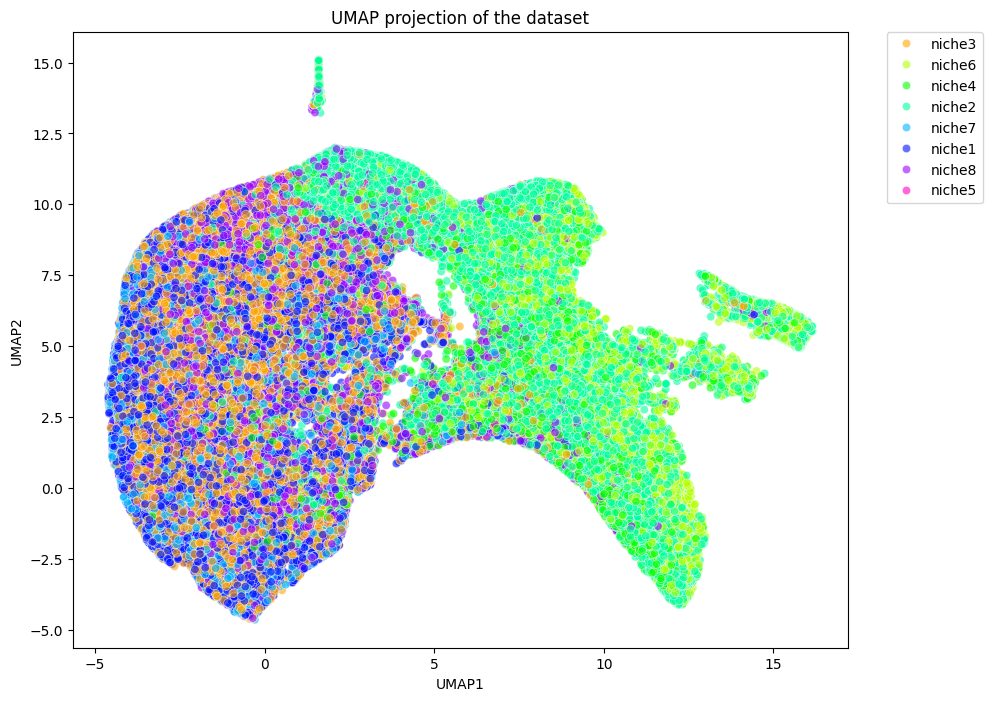

In [14]:
train_data = pd.read_csv('/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/new_data_train_niche_label.csv')
run_umap_visualization(train_data)

In [1]:
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score
from tqdm import tqdm

def prepare_dataframes(train_df, test_df, feature_prefix='feature_', label_column='cluster_label', num_features=192):
    # Extract features and labels
    feature_columns = [f'{feature_prefix}{i}' for i in range(num_features)]
    X_train = train_df[feature_columns].values
    X_test = test_df[feature_columns].values

    # Convert 'cluster_label' to integers
    le = LabelEncoder()
    y_train = le.fit_transform(train_df[label_column])
    y_test = le.transform(test_df[label_column])

    return X_train, y_train, X_test, y_test

def create_dataloaders(X_train, y_train, X_test, y_test, batch_size=32):
    # Create DataLoader
    train_dataset = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long))
    test_dataset = TensorDataset(torch.tensor(X_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.long))
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    return train_loader, test_loader

def train_model(model, train_loader):
    X_train, y_train = [], []
    for X_batch, y_batch in tqdm(train_loader):
        X_train.extend(X_batch.numpy())
        y_train.extend(y_batch.numpy())
    model.fit(X_train, y_train)

def evaluate_model(model, data_loader):
    X, y = [], []
    for X_batch, y_batch in data_loader:
        X.extend(X_batch.numpy())
        y.extend(y_batch.numpy())
    preds = model.predict(X)
    accuracy = accuracy_score(y, preds)
    f1 = f1_score(y, preds, average='macro')
    f1_weighted = f1_score(y, preds, average='weighted')
    return accuracy, f1, f1_weighted

def run_logistic_regression(train_df, test_df):
    # Prepare data
    X_train, y_train, X_test, y_test = prepare_dataframes(train_df, test_df)

    # Create DataLoaders
    train_loader, test_loader = create_dataloaders(X_train, y_train, X_test, y_test)

    # Define the logistic regression model
    model = LogisticRegression(max_iter=200, solver='lbfgs', multi_class='multinomial')

    # Train the model
    train_model(model, train_loader)

    # Evaluate the model
    train_accuracy, train_f1, train_f1_weighted = evaluate_model(model, train_loader)
    test_accuracy, test_f1, test_f1_weighted = evaluate_model(model, test_loader)

    # Print results
    print("Training Accuracy:", train_accuracy)
    print("Test Accuracy:", test_accuracy)
    print("Training Macro Average F1 Score:", train_f1)
    print("Test Macro Average F1 Score:", test_f1)
    print("Training weighted Average F1 Score:", train_f1_weighted)
    print("Test weighted Average F1 Score:", test_f1_weighted)


## nmi_ari_cluster_labels_leiden

In [62]:
# Load the DataFrame
from scib_metrics.benchmark import Benchmarker, BioConservation
biocons = BioConservation(isolated_labels=False, nmi_ari_cluster_labels_leiden=True, nmi_ari_cluster_labels_kmeans=False)


df = pd.read_csv('/lustre/scratch126/cellgen/team361/mv10/jepa/nichejepa/new_data_train_seb.csv')

# Extract feature columns and label column
feature_columns = [f'feature_{i}' for i in range(192)]  # Adjust the range if there are 193 feature columns including latent_192
label_column = 'cluster_label'

# Prepare the feature matrix X and labels
X = df[feature_columns].values
labels = df[label_column].values

# Create an AnnData object
adata = sc.AnnData(X)
adata.obs['labels'] = labels
bm = Benchmarker(
    adata,
    label_key="labels",
    bio_conservation_metrics=biocons,
    n_jobs=-1,
)
bm.prepare(neighbor_computer=faiss_brute_force_nn)
bm.benchmark()




TypeError: Benchmarker.__init__() missing 2 required positional arguments: 'batch_key' and 'embedding_obsm_keys'

In [60]:
adata

AnnData object with n_obs × n_vars = 168000 × 192
    obs: 'labels'

In [51]:
adata

AnnData object with n_obs × n_vars = 168000 × 192
    uns: 'neighbors'
    obsp: 'distances', 'connectivities'